# 03 · NLP walkthrough (Step 6): support tickets → sentiment, category, actions

Final code: `src/data/ticket_text.py`, `src/nlp/ticket_classifier.py`, `src/nlp/ticket_insights.py`.

**Business sawal:** har naya ticket (1) sahi team ko jaaye (category), (2) gussa wale tickets upar aayein
(sentiment), (3) jo customers chhodne wale hain aur naraz hain, unhe aaj call kiya jaaye.

In [1]:
import sys, os, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120); plt.rcParams["figure.figsize"] = (10, 4)
t = pd.read_csv("data/raw/tickets.csv", parse_dates=["created_at"])
print(len(t), "tickets |", t.text.nunique(), "unique texts")

10336 tickets | 9915 unique texts


## 1. Pehla sabak: data check karo, model baad mein
Pehle generator sirf **59 fixed sentences** banata tha. Us par TF-IDF aur Keras dono ne **100%** score kiya —
lekin wo sirf sentences yaad kar rahe the. Real tickets messy hote hain, isliye text dobara banaya
(`src/data/ticket_text.py`): alag wording, typos, Hinglish, sarcasm, polite complaints, bina tone wale aur
vague tickets. Labels (category, sentiment) nahi badle, isliye Steps 3-5 ke results same rahe.

In [2]:
for s in ["negative", "neutral", "positive"]:
    print(f"--- {s}")
    for x in t[t.sentiment == s].text.sample(4, random_state=7): print("  ", x)

--- negative
   Hello team, Battery of the laptop drains very fast. I would appreciate it if this is sorted soon, it has been a while.
   Last order ke baare mein help chahiye. Bakwas service. Pls check asap.
   Tracking update nahi ho rahi. Paisab arbaad hog aya. Pls cheeck asap.
   What material is the printer made of. If not fixed I will cancel my account.
--- neutral
   Hi suupport, Please send the GST innvoice for my shoes. Regards.
   Dear team, My card was debited but the order failed. Let me know the next steps. Kindly do the needful.
   What material is the shoes made of. Can you help with this?
   please send the gst invvoice for myj acket. also the refund is still pending. what should i do?
--- positive
   hi there, product bahut accha hai. password reset kaise karu. thanks.
   Namaste, The courier did not show up on the promised date. Thanks for the quick support last time!
   Great service as always, just a small query. The stapler I ordered is delayed by 15 days. Please h

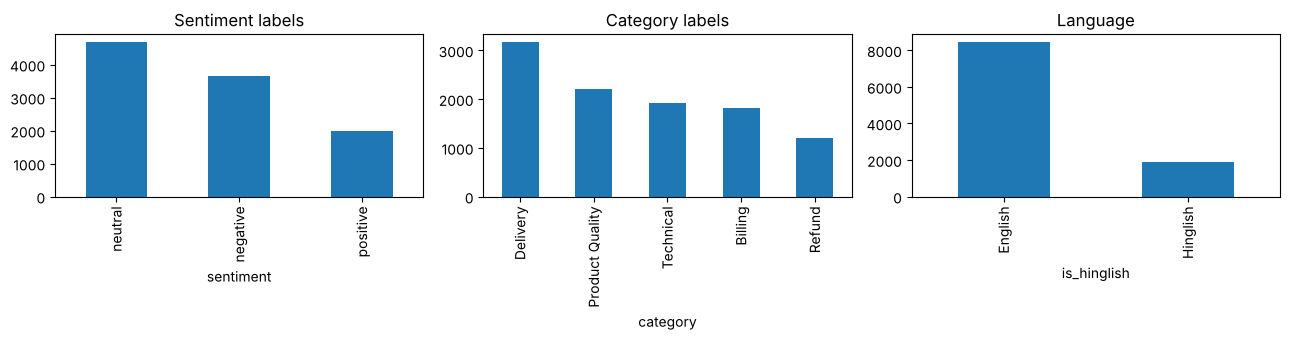

In [3]:
from src.nlp.ticket_classifier import HINGLISH
t["is_hinglish"] = t.text.str.contains(HINGLISH)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
t.sentiment.value_counts().plot(kind="bar", ax=ax[0], title="Sentiment labels")
t.category.value_counts().plot(kind="bar", ax=ax[1], title="Category labels")
t.is_hinglish.map({True: "Hinglish", False: "English"}).value_counts().plot(kind="bar", ax=ax[2], title="Language")
plt.tight_layout(); plt.show()

## 2. Split: time-based
train < 2025-07 · valid 2025-07..12 (model + threshold choose) · test 2026 (sirf ek baar).
Random split mein ek hi customer ke milte-julte tickets train aur test dono mein chale jaate — score jhootha.

In [4]:
from src.nlp import ticket_classifier as N
train = t[t.created_at < N.VALID_START]; valid = t[(t.created_at >= N.VALID_START) & (t.created_at < N.TEST_START)]
print(len(train), len(valid))

6045 1572


## 3. Baseline: keyword rules
Har model ko pehle insaan ke likhe rules se behtar hona chahiye.

In [5]:
kw = valid.text.map(N.keyword_sentiment)
print("keyword sentiment:", N.scores(valid.sentiment, kw, N.TASKS["sentiment"]))
print("keyword category :", N.scores(valid.category, valid.text.map(N.keyword_category), N.TASKS["category"]))

keyword sentiment: {'accuracy': 0.704, 'macro_f1': 0.686}
keyword category : {'accuracy': 0.812, 'macro_f1': 0.813}


## 4. TF-IDF + Logistic Regression
- **word n-grams** (1-2 words): "not received", "worst experience"
- **character n-grams** (2-5 letters): "refnd" aur "refund" ke bahut se tukde same hain → typos aur Hinglish
  spellings ke saath bhi kaam karta hai

In [6]:
m = N.tfidf_model().fit(train, train.sentiment)
pred = m.predict(valid)
print("tfidf sentiment:", N.scores(valid.sentiment, pred, N.TASKS["sentiment"]))
# model ne kya seekha? samjhne ke liye ek chhota single-word model (asli model mein char n-grams bhi hain)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
vec = TfidfVectorizer(min_df=5, token_pattern=r"(?u)\b[a-z]{3,}\b"); X = vec.fit_transform(train.text.str.lower())
lr = LogisticRegression(max_iter=2000, C=1.0).fit(X, train.sentiment)
names = vec.get_feature_names_out()
for i, c in enumerate(lr.classes_):
    print(f"{c:9s}", ", ".join(names[lr.coef_[i].argsort()[::-1][:10]]))

tfidf sentiment: {'accuracy': 0.803, 'macro_f1': 0.795}
negative  experience, unacceptable, will, frustrating, fed, again, acceptable, sadly, bakwas, useless
neutral   should, check, can, update, please, what, share, know, next, steps
positive  quick, product, response, happy, guys, awesome, accha, best, appreciate, love


## 5. Error analysis — galti kahan ho rahi hai?

In [7]:
from src.data.ticket_text import TONE, VAGUE
v = valid.assign(pred=pred)
tones = [x.lower().rstrip(".!")[:18] for d in TONE.values() for l in d.values() for x in l if x]
v["has_tone"] = v.text.str.lower().apply(lambda s: any(x in s for x in tones))
v.assign(correct=v.sentiment == v.pred).groupby("has_tone").correct.agg(["mean", "size"])

,mean,size
has_tone,,
False,0.511811,635
True,1.000000,937


**Jahan tone hai wahan ~100% sahi, jahan tone nahi wahan ~50%.** "My refund has not been received." —
ye neutral hai ya negative? Text mein jawab hai hi nahi. Bada model (BERT bhi) yahan madad nahi karega.
Isliye text ke **bahar** ki jaankari chahiye → customer ne ticket kholte waqt jo **priority** chuni.

In [8]:
pd.crosstab(t.priority, t.sentiment, normalize="index").round(2)

sentiment,negative,neutral,positive
priority,,,
High,1.00,0.00,0.00
Low,0.19,0.57,0.25
Medium,0.19,0.57,0.24


In [9]:
m2 = N.tfidf_model(use_priority=True).fit(train, train.sentiment)
pred2 = m2.predict(valid)
print("text only      :", N.scores(valid.sentiment, pred, N.TASKS["sentiment"]))
print("text + priority:", N.scores(valid.sentiment, pred2, N.TASKS["sentiment"]))

text only      : {'accuracy': 0.803, 'macro_f1': 0.795}
text + priority: {'accuracy': 0.865, 'macro_f1': 0.851}


## 6. Saare models ek saath (pipeline ka result)
Keras BiGRU (deep learning) bhi try kiya — `python -m src.nlp.ticket_classifier` ka output:

In [10]:
r = json.load(open("reports/nlp_metrics.json"))
cmp = pd.DataFrame({task: {n: v["macro_f1"] for n, v in res.items()} for task, res in r["validation_comparison"].items()})
print("Validation macro-F1:"); display(cmp)
print("Selected:", r["selected"])

Validation macro-F1:


,sentiment,category
keyword,0.686,0.813
tfidf_lr,0.795,0.949
tfidf_lr_priority,0.851,0.952
keras_bigru,0.791,0.946


Selected: {'sentiment': 'tfidf_lr_priority', 'category': 'tfidf_lr'}


Keras BiGRU TF-IDF jitna hi aaya, zyada nahi. Chhote data (~7k tickets) par simple model aksar barabar
ya behtar hota hai — aur wo tez, sasta aur samjhne layak hai. **Rule:** fark 0.005 se kam ho toh simple model chuno.

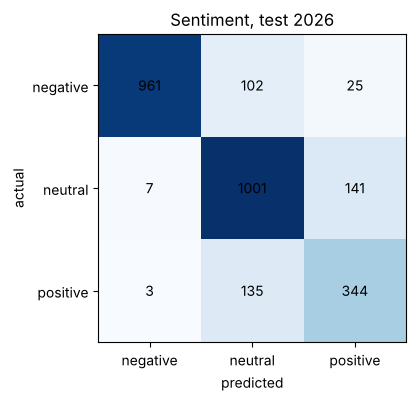

In [11]:
cm = r["test"]["sentiment"]["confusion_matrix"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm["matrix"], cmap="Blues")
ax.set_xticks(range(3), cm["labels"]); ax.set_yticks(range(3), cm["labels"])
for i in range(3):
    for j in range(3): ax.text(j, i, cm["matrix"][i][j], ha="center", va="center")
ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title("Sentiment, test 2026"); plt.show()

## 7. Human-in-the-loop: kab model par bharosa karein?
Model har ticket ke saath ek probability deta hai. Kam confidence → insaan dekhe.

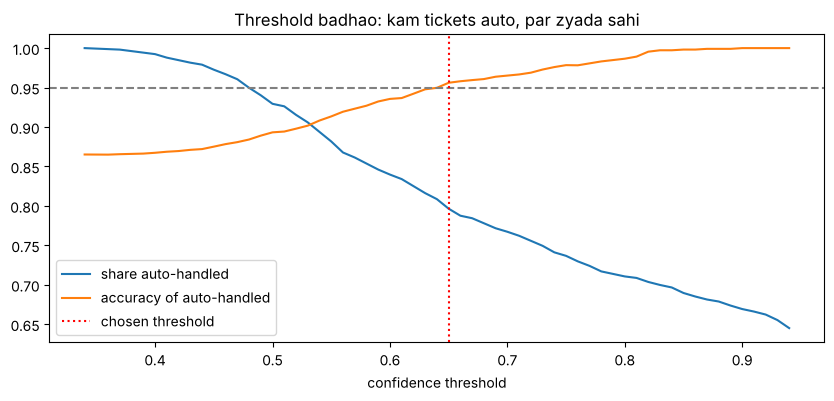

{'threshold': 0.65,
 'auto_handled_share': 0.794,
 'accuracy_auto_handled': 0.944,
 'accuracy_sent_to_review': 0.478}

In [12]:
proba = m2.predict_proba(valid); conf = proba.max(1); ok = (m2.classes_[proba.argmax(1)] == valid.sentiment.values)
th = np.arange(0.34, 0.95, 0.01)
cov = [(conf >= x).mean() for x in th]; acc = [ok[conf >= x].mean() for x in th]
plt.plot(th, cov, label="share auto-handled"); plt.plot(th, acc, label="accuracy of auto-handled")
plt.axhline(0.95, ls="--", c="gray"); plt.axvline(r["review_thresholds"]["sentiment"], c="r", ls=":", label="chosen threshold")
plt.xlabel("confidence threshold"); plt.legend(); plt.title("Threshold badhao: kam tickets auto, par zyada sahi"); plt.show()
r["test"]["sentiment"]["human_in_the_loop"]

## 8. Business insights (`src/nlp/ticket_insights.py`)

In [13]:
ins = json.load(open("reports/ticket_insights.json"))
display(pd.DataFrame(ins["category_trend"])[["category", "tickets_per_month_last_3m", "negative_share_prev_9m",
                                             "negative_share_last_3m", "change_pp", "status"]])
for cat, ph in ins["complaint_themes"].items():
    print(f"{cat:16s}", " | ".join(f"{p['phrase']} ({p['tickets']})" for p in ph[:3]))

,category,tickets_per_month_last_3m,negative_share_prev_9m,negative_share_last_3m,change_pp,status
0,Product Quality,62.0,0.363,0.392,3.0,stable
1,Refund,31.7,0.344,0.358,1.4,stable
2,Delivery,84.7,0.373,0.299,-7.3,improving
3,Billing,46.7,0.392,0.300,-9.2,improving
4,Technical,52.0,0.354,0.237,-11.7,improving


Billing          debited but the order (14) | card was debited (13) | coupon code gave (13)
Delivery         courier did not show (21) | up on the promised (21) | address for order (19)
Product Quality  working within a week (14) | came off after one (13) | delivery was fine though (13)
Refund           refund is pending (12) | been days and still (8) | timeline for returned items (8)
Technical        how do i reset (17) | reset my password (16) | coming on my phone (10)


In [14]:
urgent = pd.read_csv("data/processed/urgent_tickets.csv")
print(len(urgent), "customers to call today")
urgent.head(8)

87 customers to call today


,customer_id,segment_name,segment,churn_probability,revenue_at_risk_365d,ticket_id,created_at,pred_category,priority,text
0,C01658,Champions,SMB,0.601,315038.0,T010184,2026-09-09,Product Quality,High,Battery of the headphones drains very fast. Thanks.
1,C00974,Champions,Corporate,0.132,303918.0,T010101,2026-08-30,Billing,Low,"Hi there, EMI option is not showing on my card. I would appreciate it if this is sorted soon, it has been a while. P..."
2,C02222,Champions,SMB,0.157,137212.0,T009953,2026-08-15,Refund,Medium,"Dear team, 15 din ho gaye refund nahi mila. Paisa barbaad ho gaya."
3,C01430,Big-ticket buyers,Corporate,0.082,121132.0,T009812,2026-08-02,Product Quality,Medium,"Hi, Stapler ek hafte mein kharab ho gaya. Thanks!!!"
4,C01832,Champions,SMB,0.203,108919.0,T010203,2026-09-11,Technical,Medium,How do I reset my password. I am fed up of following up. Kindly do the needful.
5,C02531,Big-ticket buyers,SMB,0.307,106637.0,T010099,2026-08-30,Technical,High,Login nahi ho raha. Bahut bura experience hai. Waiting for reply.
6,C02408,Champions,SMB,0.183,83863.0,T010297,2026-09-23,Product Quality,High,I have an issue with order #928608. I want a refund or replacement. If not fixed I will cancel my account. Regards.
7,C00733,Loyal regulars,SMB,0.571,80364.0,T009978,2026-08-18,Product Quality,Medium,What material is the printer made of. If not fixed I will cancel my account.


## Takeaways
- **Pehle data dekho.** 100% score = data mein gadbad, model ki jeet nahi.
- **Error analysis > bada model.** Galtiyan "bina tone" aur "vague" tickets mein thi — wahan text mein jawab hi nahi.
  Fix = nayi jaankari (priority), naya model nahi.
- **Simple model** (TF-IDF + LR) ne Keras ko barabari di; tez, sasta, explainable.
- **Confidence threshold** se model aur insaan saath kaam karte hain.
- Asli value: NLP + churn model jod kar **"aaj kise call karna hai"** list.